In [ ]:
!pip install --upgrade binance-historical-data plotly -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 51.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 272.8/272.8 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 47.8 MB/s eta 0:00:00


In [ ]:
import os
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime, timedelta, date, time
from binance_historical_data import BinanceDataDumper
warnings.filterwarnings('ignore')

def get_list_all_trading_pairs():
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",  # spot, um, cm
        data_type="klines",  # aggTrades, klines, trades
        data_frequency="5m",
    )
    return data_dumper.get_list_all_trading_pairs()

def detect_timestamp_unit(timestamp):
    num_digits = len(str(timestamp))
    if num_digits == 13:
        return 'ms'
    elif num_digits == 16:
        return 'us'
    else:
        raise ValueError(f"Timestamp không hợp lệ: {timestamp}")

def convert_timestamp(timestamp):
    unit = detect_timestamp_unit(timestamp)
    return pd.to_datetime(timestamp, unit=unit, errors='coerce')

def download_ticker(ticker, date_start, date_end, data_frequency="1h"):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency= data_frequency,
    )
    date_start = datetime.strptime(date_start, "%Y-%m-%d").date()
    date_end = datetime.strptime(date_end, "%Y-%m-%d").date()
    data_dumper.dump_data(
        tickers = ticker,
        date_start = date_start,
        date_end = date_end,
        is_to_update_existing = False,
    )

def read_csv_file(file_path):
    df = pd.read_csv(file_path)
    df.columns = [
        "open_time", "Open", "High", "Low", "Close", "volume",
        "close_time", "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume", "ignore"
    ]
    df['open_time'] = df['open_time'].apply(convert_timestamp)
    df['close_time'] = df['close_time'].apply(convert_timestamp)
    return df

def get_csv_files(directory):
    try:
        if not os.path.exists(directory):
            print(f"Warning: Thư mục không tồn tại: {directory}")
            return []
        return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.csv')]
    except Exception as e:
        print(f"Lỗi khi đọc thư mục {directory}: {str(e)}")
        return []

# Load data from file
def process_csv_files(ticker, data_frequency = "1h"):
    daily_path = os.path.join(os.getcwd(), f"spot/daily/klines/{ticker}/{data_frequency}")
    monthly_path = os.path.join(os.getcwd(), f"spot/monthly/klines/{ticker}/{data_frequency}")
    daily_files = get_csv_files(daily_path)
    monthly_files = get_csv_files(monthly_path)
    all_files = daily_files + monthly_files
    if not all_files:
        print(f"❗ Không có file CSV nào cho {ticker}")
        return None
    data = pd.concat([read_csv_file(file) for file in all_files], ignore_index=True)
    data.sort_values(by='open_time', inplace=True)
    return data



In [ ]:
ticker = 'XRPUSDT'
data_frequency = '1d'
download_ticker(ticker, "2022-01-01", "2025-07-25", data_frequency)
data = process_csv_files(ticker, data_frequency)
data = data.drop(columns=['close_time',	'quote_asset_volume',	'number_of_trades',	'taker_buy_base_asset_volume',	'taker_buy_quote_asset_volume',	'ignore'])
data.set_index('open_time', inplace=True)
data

---> Found overall tickers: 592
---> Filter to asked tickers: 7
------> Tickers left: 2
Download full data for 2 tickers: 
---> Data will be saved here: /content/spot
---> Data Frequency: 1d
---> Start Date: 20220101
---> End Date: 20250725


Tickers:   0%|          | 0/2 [00:00<?, ?it/s]

monthly files to download:   0%|          | 0/42 [00:00<?, ?files/s]

daily files to download:   0%|          | 0/25 [00:00<?, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

Tried to dump data for 2 tickers:
---> For XRPUSDT new data saved for: 42 months 25 days
---> For XRPUSD new data saved for: 0 months 0 days


,Open,High,Low,Close,volume
open_time,,,,,
2022-01-02,0.8508,0.8667,0.8372,0.8586,129688032.0
2022-01-03,0.8586,0.8587,0.8213,0.8324,178618617.0
2022-01-04,0.8324,0.8456,0.7794,0.8228,214415744.0
2022-01-05,0.8227,0.8372,0.7092,0.7726,370612510.0
2022-01-06,0.7725,0.7909,0.7377,0.7791,307202277.0
...,...,...,...,...,...
2025-06-26,2.1858,2.2127,2.0956,2.1054,120378866.1
2025-06-27,2.1053,2.1556,2.0671,2.1419,120577000.3
2025-06-28,2.1420,2.2079,2.1336,2.1854,70042779.0


In [ ]:
# Calculate the 5-day moving average for High and Low prices
df = data.copy()
df['SMA_High'] = df['High'].rolling(window=5).mean()
df['SMA_Low'] = df['Low'].rolling(window=5).mean()

# Calculate the Upperbound and Lowerbound
df['Upperbound'] = df['SMA_High'] - 0.2 * (df['SMA_High'] - df['SMA_Low'])
df['Lowerbound'] = df['SMA_Low'] + 0.2 * (df['SMA_High'] - df['SMA_Low'])

price = df['Open']
sma_high = df['SMA_High']
sma_low = df['SMA_Low']
upperbound = df['Upperbound']
lowerbound = df['Lowerbound']
df.head (10) # Display the DataFrame

,Open,High,Low,Close,volume,SMA_High,SMA_Low,Upperbound,Lowerbound
open_time,,,,,,,,,
2022-01-02,0.8508,0.8667,0.8372,0.8586,129688032.0,NaN,NaN,NaN,NaN
2022-01-03,0.8586,0.8587,0.8213,0.8324,178618617.0,NaN,NaN,NaN,NaN
2022-01-04,0.8324,0.8456,0.7794,0.8228,214415744.0,NaN,NaN,NaN,NaN
2022-01-05,0.8227,0.8372,0.7092,0.7726,370612510.0,NaN,NaN,NaN,NaN
2022-01-06,0.7725,0.7909,0.7377,0.7791,307202277.0,0.83982,0.77696,0.827248,0.789532
2022-01-07,0.7790,0.7808,0.7287,0.7634,372926762.0,0.82264,0.75526,0.809164,0.768736
2022-01-08,0.7634,0.7768,0.7222,0.7452,253028571.0,0.80626,0.73544,0.792096,0.749604
2022-01-09,0.7452,0.7667,0.7381,0.7530,151521399.0,0.79048,0.72718,0.777820,0.739840
2022-01-10,0.7530,0.7589,0.6967,0.7399,313080154.0,0.77482,0.72468,0.764792,0.734708


In [ ]:
for i in range(len(price)-10, len(price)):
  # Vị thế hiện tại - inpos
  if (price[i] > upperbound[i-1]):
    print ("TRUE")
  else:
    print ('false')

false
false
false
TRUE
TRUE
TRUE
false
false
false
TRUE


In [ ]:
# pnls = []
# entry = None
# pnl = 0
# dates =[]
# unrlzd = []
# unrlzd_dates = []
# inpos = 0
# holdtime = []
# COMMS = 0.002 #Fee per trade = 0.001
# #maxdrawdown
# #frequency
# #winrate

# for i in range(1, len(price)): # Start loop from index 1 to avoid accessing price[-1]
#   unr = (price.iloc[i] / price.iloc[i-1] -1) * inpos
#   unrlzd.append(unr)
#   unrlzd_dates.append(price.index[i])

#   if (price.iloc[i] > upperbound.iloc[i-1]):
#     if entry:
#       pnl = price.iloc[i] / entry -1
#       pnls.append(pnl)
#       dates.append(price.index[i])
#       # holdtime.append((price.index[i] - start).total_seconds())

#     entry = price.iloc[i]
#     inpos = -1
#     start = price.index[i] # Keep original index for 'start' if needed for holdtime
#     unrlzd[-1] -= COMMS/2
#     #print('Entry short', pnl)

#   elif (price.iloc[i] < lowerbound.iloc[i-1]): # Use .iloc for consistent indexing
#     if entry:
#       pnl = entry / price.iloc[i] -1
#       pnls.append(pnl)
#       dates.append(price.index[i])
#       # holdtime.append((price.index[i] - start).total_seconds())

#     entry = price.iloc[i]
#     inpos = 1
#     start = price.index[i] # Keep original index for 'start' if needed for holdtime
#     unrlzd[-1] -= COMMS/2
#     #print('Entry long', pnl, dates[-1])

In [ ]:
dates = []
pnls = []
unrealised_dates = []
unrealised = []
inpos = 0
entry = 0
COMMS = 0.002 #Fee per trade = 0.001 0,1%

for i in range(1, len(price)-1):
  # Vị thế hiện tại - inpos
  if (price[i] > upperbound[i-1]): # and (upperbound[i-1] > upperbound[i-2]): and (upperbound[i-2] > upperbound[i-3]):
    if entry !=0 and inpos != 1:
      exit = price [i]
      dates.append(price.index[i])
      pnls.append((exit - COMMS/2)/entry-1)
    entry = price[i]
    inpos = 1
  elif (price[i] < lowerbound[i-1]): #and (lowerbound[i-1] < lowerbound[i-2]): and (lowerbound[i-2] < lowerbound[i-3]):
    if entry !=0 and inpos != -1:
      exit = price [i]
      dates.append(price.index[i])
      pnls.append((entry - COMMS/2)/exit-1)
    entry = price[i]
    inpos = -1

  # Profit from position
  unrealised_dates.append(price.index[i])
  if inpos == 1:
    unrealised.append(price[i+1]/price[i] -1)
  elif inpos == -1:
    unrealised.append(price[i]/price[i+1] -1)
  else:
    unrealised.append(0)


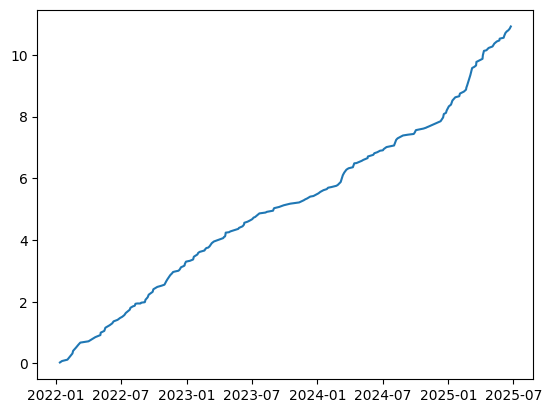

In [ ]:
# Plot profit
# plt.plot(unrealised_dates, np.cumprod(1+np.array(unrealised))-1)
# plt.plot(dates, np.cumprod(1+np.array(pnls))-1)
#plt.plot(dates,np.cumprod(1+np.array(pnls))-1)
# plt.plot(unrlzd_dates,np.cumprod(1+np.array(unrlzd)))
plt.plot(dates, np.cumsum(pnls))
#plt.plot(unrlzd_dates, np.cumsum(unrlzd))

In [ ]:
# Check if mean reversion signal has statistical significance